## 1. Setup

Use Python 3.10 or newer with JupyterLab or Jupyter Notebook. If needed, uncomment
and run the installation line below, then restart the kernel. Only NumPy, SciPy,
and Plotly are required by the lesson code.

In [2]:
# %pip install numpy scipy plotly

import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy.stats import multivariate_normal
from scipy.special import expit

np.set_printoptions(precision=3, suppress=True)
pio.templates.default = "plotly_white"
pio.renderers.default = "plotly_mimetype"

# If your notebook interface shows blank plots, try:
# pio.renderers.default = "notebook"

COLORS = {1: "#2563EB", 2: "#EA580C"}
SCORE_COLORS = [[0, "#EA580C"], [0.5, "#FFFFFF"], [1, "#2563EB"]]

## 2. Generate two Gaussian clouds

We generate
$$
X\mid C=k\sim\mathcal N(\mu_k,\Sigma),\qquad k\in\{1,2\}.
$$
The two classes have different means and the **same covariance matrix**.
The positive off-diagonal entries make the clouds tilt upward.
The fixed random seed makes the example reproducible.

For the first example we deliberately choose equal priors, $\pi_1=\pi_2=0.5$.
The sample sizes are also equal, but priors are a modelling choice: they need not
always equal the proportions in a collected dataset.

In [3]:
rng = np.random.default_rng(12)
n_per_class = 180

true_mean_1 = np.array([-1.4, -0.6])
true_mean_2 = np.array([1.4, 0.6])
true_covariance = np.array([
    [1.8, 1.2],
    [1.2, 1.5],
])

X1 = rng.multivariate_normal(true_mean_1, true_covariance, n_per_class)
X2 = rng.multivariate_normal(true_mean_2, true_covariance, n_per_class)
X = np.vstack([X1, X2])
y = np.concatenate([np.ones(n_per_class), 2 * np.ones(n_per_class)])

prior_1 = 0.5
prior_2 = 0.5

# Use the same plotting window for all main 2D plots.
x_range = [X[:, 0].min() - 0.8, X[:, 0].max() + 0.8]
y_range = [X[:, 1].min() - 0.8, X[:, 1].max() + 0.8]

Two small plotting helpers keep the later cells focused on the mathematics.
Neither helper fits a model or computes a prediction.

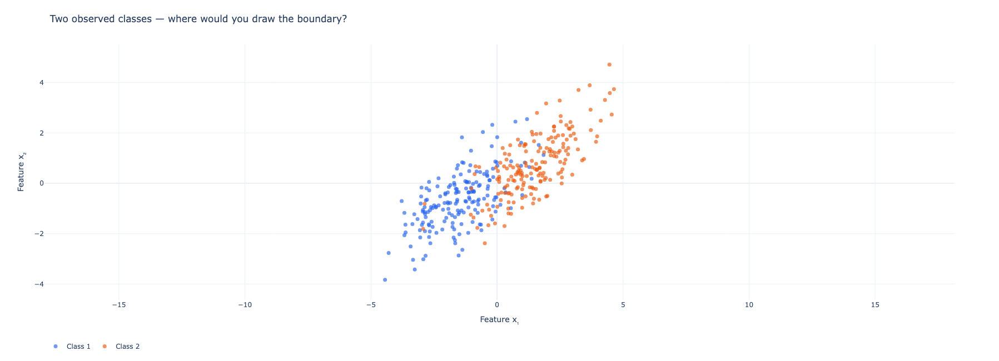

In [4]:
def add_observations(fig):
    """Add the two observed classes to a 2D figure."""
    for points, label in [(X1, 1), (X2, 2)]:
        fig.add_trace(go.Scatter(
            x=points[:, 0], y=points[:, 1],
            mode="markers", name=f"Class {label}",
            marker=dict(color=COLORS[label], size=7, opacity=0.65),
            hovertemplate="x₁=%{x:.2f}<br>x₂=%{y:.2f}<extra>%{fullData.name}</extra>",
        ))
    return fig


def format_2d(fig, title):
    """Keep feature axes and aspect ratio consistent across figures."""
    fig.update_layout(
        title=title, width=850, height=650,
        xaxis=dict(title="Feature x₁", range=x_range),
        yaxis=dict(title="Feature x₂", range=y_range,
                   scaleanchor="x", scaleratio=1),
        legend=dict(orientation="h", y=-0.15),
        margin=dict(t=80, b=100),
    )
    return fig


fig = add_observations(go.Figure())
format_2d(fig, "Two observed classes — where would you draw the boundary?").show()

## 3. Estimate the Gaussian model

First estimate each mean and each within-class sample covariance. Then combine
the covariances using their degrees of freedom:
$$
\hat\Sigma=\frac{(n_1-1)S_1+(n_2-1)S_2}{n_1+n_2-2}.
$$
We use the conventional **unbiased pooled within-class covariance**. The maximum
likelihood estimate instead divides the same scatter sum by $n_1+n_2$.
Use the convention from your course consistently; the choice can affect the
boundary when priors are unequal.

Even though the generating covariances are identical, $S_1$ and $S_2$ will generally
differ due to sampling variation. **Both fitted LDA Gaussians use $\hat\Sigma$.**
Do not use the covariance of all observations around the overall mean: that also
includes between-class variation.

In [5]:
n1, n2 = len(X1), len(X2)
mean_1 = X1.mean(axis=0)
mean_2 = X2.mean(axis=0)

covariance_1 = np.cov(X1, rowvar=False, ddof=1)
covariance_2 = np.cov(X2, rowvar=False, ddof=1)
pooled_covariance = (
    (n1 - 1) * covariance_1 + (n2 - 1) * covariance_2
) / (n1 + n2 - 2)

print("Estimated mean, class 1:", mean_1)
print("Estimated mean, class 2:", mean_2)
print("\nSample covariance, class 1:\n", covariance_1)
print("\nSample covariance, class 2:\n", covariance_2)
print("\nShared pooled covariance:\n", pooled_covariance)
print("\nChosen class priors:", prior_1, prior_2)
print("\nGenerating covariance, for comparison:\n", true_covariance)

Estimated mean, class 1: [-1.486 -0.651]
Estimated mean, class 2: [1.465 0.73 ]

Sample covariance, class 1:
 [[1.516 0.868]
 [0.868 1.25 ]]

Sample covariance, class 2:
 [[1.708 1.169]
 [1.169 1.518]]

Shared pooled covariance:
 [[1.612 1.018]
 [1.018 1.384]]

Chosen class priors: 0.5 0.5

Generating covariance, for comparison:
 [[1.8 1.2]
 [1.2 1.5]]


### Overlay the fitted density contours

Evaluate both fitted densities on a grid. Using identical contour levels for
both classes makes their shapes comparable. These are **density levels**, not
probabilities or regions containing a stated percentage of observations.

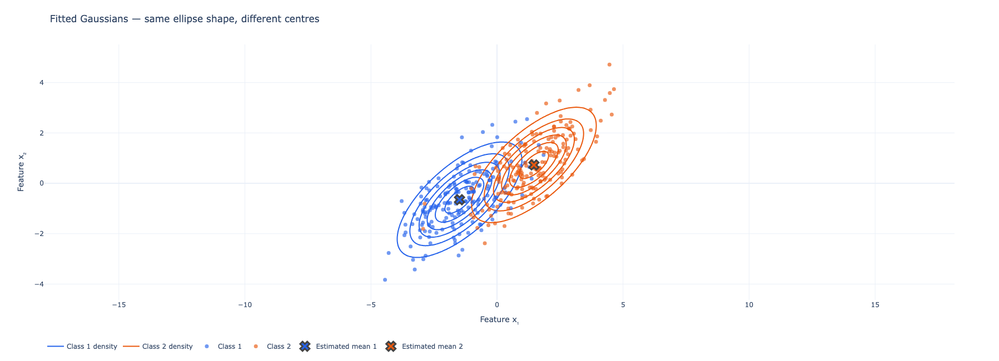

In [6]:
grid_x = np.linspace(*x_range, 150)
grid_y = np.linspace(*y_range, 150)
xx, yy = np.meshgrid(grid_x, grid_y)
grid_points = np.column_stack([xx.ravel(), yy.ravel()])

gaussian_1 = multivariate_normal(mean=mean_1, cov=pooled_covariance)
gaussian_2 = multivariate_normal(mean=mean_2, cov=pooled_covariance)
density_1 = gaussian_1.pdf(grid_points).reshape(xx.shape)
density_2 = gaussian_2.pdf(grid_points).reshape(xx.shape)

peak_density = 1 / (2 * np.pi * np.sqrt(np.linalg.det(pooled_covariance)))
contour_levels = dict(
    start=0.15 * peak_density,
    end=0.90 * peak_density,
    size=0.15 * peak_density,
    coloring="none",
)


def add_density_contours(fig):
    """Draw the two fitted Gaussian densities at matching levels."""
    for density, label in [(density_1, 1), (density_2, 2)]:
        fig.add_trace(go.Contour(
            x=grid_x, y=grid_y, z=density,
            contours=contour_levels,
            line=dict(color=COLORS[label], width=2),
            showscale=False, name=f"Class {label} density",
            hovertemplate="Density=%{z:.4f}<extra>%{fullData.name}</extra>",
        ))
    return fig


fig = add_density_contours(go.Figure())
add_observations(fig)
for mean, label in [(mean_1, 1), (mean_2, 2)]:
    fig.add_trace(go.Scatter(
        x=[mean[0]], y=[mean[1]], mode="markers",
        marker=dict(symbol="x", size=15, color=COLORS[label], line_width=3),
        name=f"Estimated mean {label}",
    ))
format_2d(fig, "Fitted Gaussians — same ellipse shape, different centres").show()

### Lift the contours into density surfaces

Height now represents $f_k(x)$, the density under class $k$.
With equal priors, assign a point to the class with the taller surface at that
location. Rotate the plot to inspect the crossing; return to the contour view
when comparing positions precisely. Transparency can obscure depth in 3D.

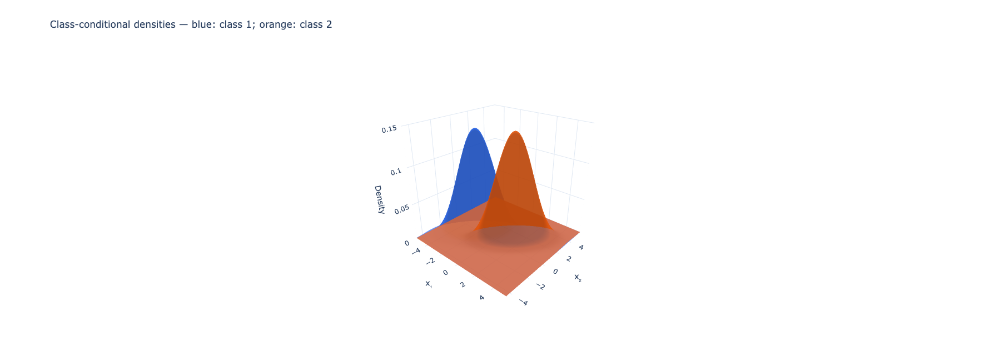

In [7]:
fig = go.Figure()
for density, label in [(density_1, 1), (density_2, 2)]:
    fig.add_trace(go.Surface(
        x=grid_x, y=grid_y, z=density,
        colorscale=[[0, COLORS[label]], [1, COLORS[label]]],
        opacity=0.72, showscale=False, name=f"Class {label}",
        hovertemplate="x₁=%{x:.2f}<br>x₂=%{y:.2f}<br>Density=%{z:.4f}"
                      "<extra>%{fullData.name}</extra>",
    ))
fig.update_layout(
    title="Class-conditional densities — blue: class 1; orange: class 2",
    width=900, height=650,
    scene=dict(xaxis_title="x₁", yaxis_title="x₂", zaxis_title="Density",
               xaxis_range=x_range, yaxis_range=y_range,
               camera=dict(eye=dict(x=1.5, y=-1.7, z=1.1))),
)
fig.show()

## 4. Compute the LDA scores

Expanding $\log\{\pi_k f_k(x)\}$ gives a shared term plus
$$
\delta_k(x)=x^T\hat\Sigma^{-1}\hat\mu_k
-\tfrac12\hat\mu_k^T\hat\Sigma^{-1}\hat\mu_k+\log\pi_k.
$$
The omitted term includes $-\tfrac12x^T\hat\Sigma^{-1}x$ and is identical
for both classes. It cancels when we subtract the scores:
$$
g(x)=\delta_1(x)-\delta_2(x)=w^Tx+b,
$$

$$
w=\hat\Sigma^{-1}(\hat\mu_1-\hat\mu_2),\qquad
b=-\tfrac12\hat\mu_1^T\hat\Sigma^{-1}\hat\mu_1
+\tfrac12\hat\mu_2^T\hat\Sigma^{-1}\hat\mu_2
+\log(\pi_1/\pi_2).
$$
**Classify as class 1 when $g(x)>0$, and class 2 when $g(x)<0$.**
The boundary is $g(x)=0$. Exact ties can be assigned either label.

We use `np.linalg.solve(Sigma, mu)` to compute $\Sigma^{-1}\mu$ without explicitly
forming the inverse. It expresses the same mathematics and is numerically preferable.

In [8]:
coefficient_1 = np.linalg.solve(pooled_covariance, mean_1)
coefficient_2 = np.linalg.solve(pooled_covariance, mean_2)

intercept_1 = -0.5 * mean_1 @ coefficient_1 + np.log(prior_1)
intercept_2 = -0.5 * mean_2 @ coefficient_2 + np.log(prior_2)

w = coefficient_1 - coefficient_2
b = intercept_1 - intercept_2

score_1 = grid_points @ coefficient_1 + intercept_1
score_2 = grid_points @ coefficient_2 + intercept_2
score_difference = (score_1 - score_2).reshape(xx.shape)

print("Coefficient for class 1:", coefficient_1)
print("Coefficient for class 2:", coefficient_2)
print("Intercept for class 1:", round(intercept_1, 3))
print("Intercept for class 2:", round(intercept_2, 3))
print("\nw =", w)
print("b =", round(b, 3))
print(f"Boundary: ({w[0]:.3f}) x₁ + ({w[1]:.3f}) x₂ + ({b:.3f}) = 0")

Coefficient for class 1: [-1.167  0.388]
Coefficient for class 2: [ 1.075 -0.263]
Intercept for class 1: -1.433
Intercept for class 2: -1.384

w = [-2.242  0.651]
b = -0.049
Boundary: (-2.242) x₁ + (0.651) x₂ + (-0.049) = 0


### A worked prediction for one point

Change `example_point` and rerun this cell. The posterior probability is a
logistic transformation of the score difference:
$P(C=1\mid x)=1/(1+\exp[-g(x)])$.

In [9]:
example_point = np.array([-2.0, -2.0])
example_score_1 = example_point @ coefficient_1 + intercept_1
example_score_2 = example_point @ coefficient_2 + intercept_2
example_difference = example_score_1 - example_score_2
example_probability = expit(example_difference)

print("Point:", example_point)
print(f"δ₁ = {example_score_1:.3f}; δ₂ = {example_score_2:.3f}")
print(f"g(x) = {example_difference:.3f}")
print(f"P(class 1 | x) = {example_probability:.3f}")
print("Predicted class:", 1 if example_difference >= 0 else 2)

Point: [-2. -2.]
δ₁ = 0.124; δ₂ = -3.008
g(x) = 3.132
P(class 1 | x) = 0.958
Predicted class: 1


### The zero contour is the decision boundary

Blue means a positive score difference (class 1); orange means a negative
difference (class 2). The black line is the zero contour. Equal score differences
lie on parallel straight lines.

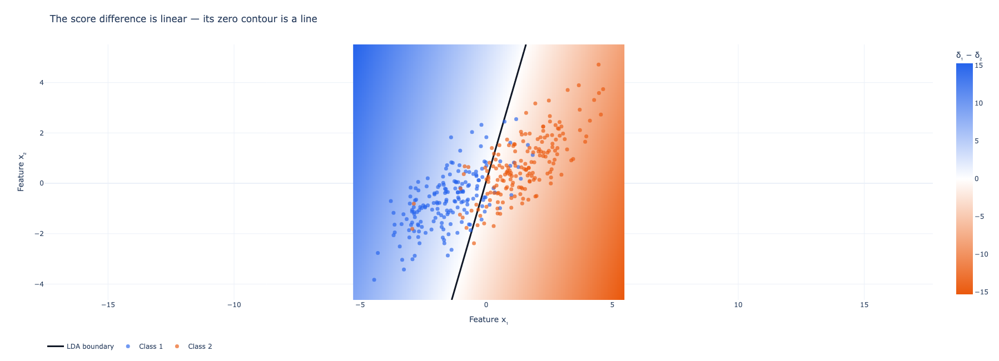

In [10]:
def add_boundary(fig, values, name="LDA boundary", color="#111827"):
    """Draw the zero contour of a score difference on the feature grid."""
    fig.add_trace(go.Contour(
        x=grid_x, y=grid_y, z=values,
        contours=dict(start=0, end=0, size=1, coloring="none"),
        line=dict(color=color, width=3), showscale=False,
        name=name, showlegend=True, hoverinfo="skip",
    ))
    return fig


score_limit = np.abs(score_difference).max()
fig = go.Figure(go.Heatmap(
    x=grid_x, y=grid_y, z=score_difference,
    colorscale=SCORE_COLORS, zmin=-score_limit, zmax=score_limit,
    colorbar=dict(title="δ₁ − δ₂"),
    hovertemplate="x₁=%{x:.2f}<br>x₂=%{y:.2f}<br>g(x)=%{z:.2f}<extra></extra>",
))
add_boundary(fig, score_difference)
add_observations(fig)
format_2d(fig, "The score difference is linear — its zero contour is a line").show()

## 5. Density contours versus posterior contours

These answer different questions:
- **Density:** How much density does a class model assign near this location?
- **Posterior:** Given this location, what is the model's probability of class 1?

The Gaussian density contours are ellipses. The posterior contours are parallel
straight lines, because the posterior is a monotone function of $w^Tx+b$.
The black boundary corresponds to posterior probability $0.5$.

Use the menu to switch views. A high posterior can occur far away from **both**
clouds: it measures relative support for the two classes, not whether a point
is typical of either class.

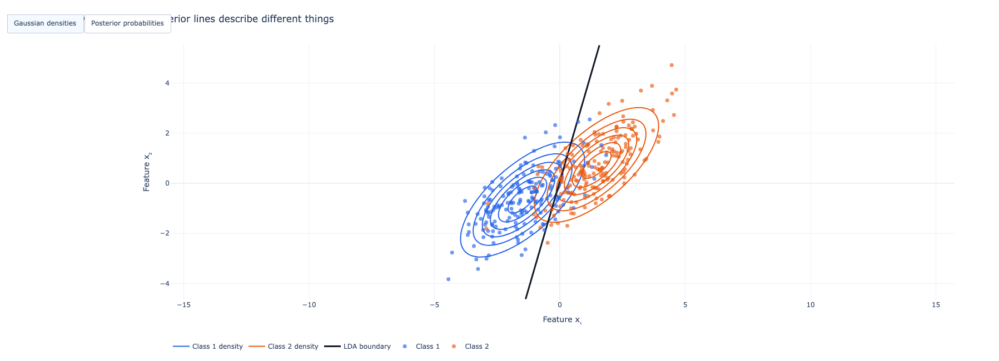

In [11]:
posterior_1 = expit(score_difference)

fig = add_density_contours(go.Figure())  # Traces 0 and 1
fig.add_trace(go.Contour(               # Trace 2
    x=grid_x, y=grid_y, z=posterior_1,
    contours=dict(start=0.1, end=0.9, size=0.1, coloring="lines", showlabels=True),
    colorscale=SCORE_COLORS, zmin=0, zmax=1,
    colorbar=dict(title="P(class 1 | x)"), visible=False,
    hovertemplate="P(class 1 | x)=%{z:.3f}<extra></extra>",
))
add_boundary(fig, score_difference)      # Trace 3
add_observations(fig)                   # Traces 4 and 5
format_2d(fig, "Density ellipses and posterior lines describe different things")
fig.update_layout(updatemenus=[dict(
    type="buttons", direction="right", x=0, y=1.12,
    buttons=[
        dict(label="Gaussian densities", method="update",
             args=[{"visible": [True, True, False, True, True, True]}]),
        dict(label="Posterior probabilities", method="update",
             args=[{"visible": [False, False, True, True, True, True]}]),
    ],
)])
fig.show()

## 6. Project onto the discriminant direction

Normalize $w$ to get the unit direction $u=w/\lVert w\rVert$. Then project each
point to the scalar $z=u^Tx$. Classification only needs this scalar:
$$
g(x)=\lVert w\rVert z+b,\qquad z_0=-b/\lVert w\rVert.
$$
Class 1 lies on the $z>z_0$ side. The normal vector points toward increasing
class-1 probability; the boundary itself is perpendicular to it.

The left panel shows the normal arrow starting at the point on the boundary
closest to the origin. On the right, all observations have been reduced to one
number. The smooth curves are the **fitted projected Gaussian densities**.

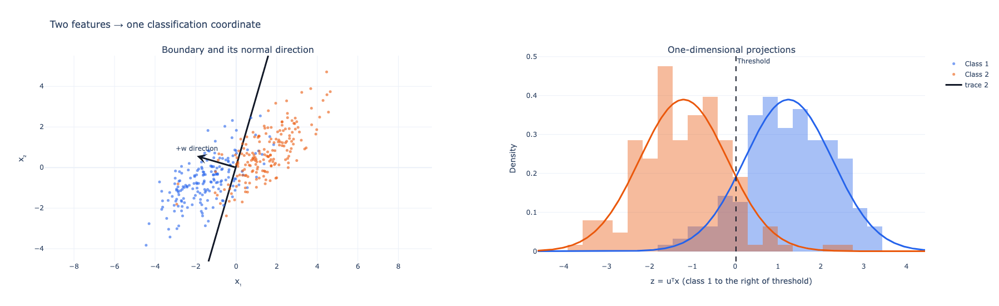

Unit discriminant direction: [-0.96   0.279]
Projected decision threshold: 0.021


In [12]:
w_norm = np.linalg.norm(w)
direction = w / w_norm
projection_1 = X1 @ direction
projection_2 = X2 @ direction
threshold = -b / w_norm

fig = make_subplots(rows=1, cols=2, subplot_titles=(
    "Boundary and its normal direction", "One-dimensional projections"
), horizontal_spacing=0.12)

for points, label in [(X1, 1), (X2, 2)]:
    fig.add_trace(go.Scatter(
        x=points[:, 0], y=points[:, 1], mode="markers",
        marker=dict(color=COLORS[label], size=5, opacity=0.6),
        name=f"Class {label}",
    ), row=1, col=1)

fig.add_trace(go.Contour(
    x=grid_x, y=grid_y, z=score_difference,
    contours=dict(start=0, end=0, size=1, coloring="none"),
    line=dict(color="#111827", width=3), showscale=False,
    hoverinfo="skip",
), row=1, col=1)

boundary_point = -b * w / (w @ w)
arrow_tip = boundary_point + 2 * direction
fig.add_annotation(
    x=arrow_tip[0], y=arrow_tip[1], ax=boundary_point[0], ay=boundary_point[1],
    xref="x", yref="y", axref="x", ayref="y",
    text="", showarrow=True, arrowhead=3, arrowwidth=3, arrowcolor="#111827",
)
fig.add_annotation(x=arrow_tip[0], y=arrow_tip[1], text="+w direction",
                   showarrow=False, yshift=15, xref="x", yref="y")

projected_sd = np.sqrt(direction @ pooled_covariance @ direction)
z_grid = np.linspace(min(projection_1.min(), projection_2.min()) - 1,
                     max(projection_1.max(), projection_2.max()) + 1, 300)

for values, mean, label in [(projection_1, mean_1, 1), (projection_2, mean_2, 2)]:
    fig.add_trace(go.Histogram(
        x=values, histnorm="probability density",
        xbins=dict(start=z_grid[0], end=z_grid[-1], size=0.35),
        marker_color=COLORS[label], opacity=0.4, showlegend=False,
    ), row=1, col=2)
    projected_mean = direction @ mean
    projected_density = np.exp(-0.5 * ((z_grid - projected_mean) / projected_sd)**2)
    projected_density /= np.sqrt(2 * np.pi) * projected_sd
    fig.add_trace(go.Scatter(
        x=z_grid, y=projected_density, mode="lines",
        line=dict(color=COLORS[label], width=3), showlegend=False,
    ), row=1, col=2)

fig.add_vline(x=threshold, line_color="#111827", line_dash="dash",
              annotation_text="Threshold", row=1, col=2)
fig.update_xaxes(title_text="x₁", range=x_range, row=1, col=1)
fig.update_yaxes(title_text="x₂", range=y_range, scaleanchor="x", scaleratio=1,
                 row=1, col=1)
fig.update_xaxes(title_text="z = uᵀx (class 1 to the right of threshold)", row=1, col=2)
fig.update_yaxes(title_text="Density", row=1, col=2)
fig.update_layout(title="Two features → one classification coordinate",
                   width=1100, height=550, barmode="overlay")
fig.show()

print("Unit discriminant direction:", direction)
print("Projected decision threshold:", round(threshold, 3))

## 7. Change the priors: move the boundary

Keep the observations, estimated means and pooled covariance fixed. Only change
$\pi_1$, with $\pi_2=1-\pi_1$.
The normal $w$ stays fixed; the intercept changes by the log prior odds.

**Predict first:** If class 1 becomes more common, which class gains decision area?

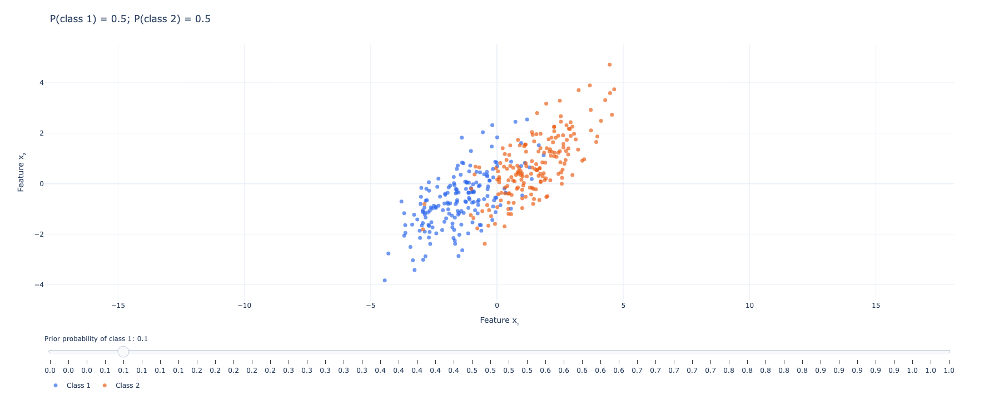

In [13]:
prior_values = np.linspace(0.0001, 0.99999, 50)
equal_prior_intercept = -0.5 * mean_1 @ coefficient_1 + 0.5 * mean_2 @ coefficient_2

fig = add_observations(go.Figure())
for p1 in prior_values:
    new_b = equal_prior_intercept + np.log(p1 / (1 - p1))
    new_scores = (grid_points @ w + new_b).reshape(xx.shape)
    add_boundary(fig, new_scores, name="Decision boundary")
    fig.data[-1].visible = bool(np.isclose(p1, 0.5))

steps = []
for index, p1 in enumerate(prior_values):
    visible = [True, True] + [i == index for i in range(len(prior_values))]
    steps.append(dict(
        label=f"{p1:.1f}", method="update",
        args=[{"visible": visible},
              {"title": f"P(class 1) = {p1:.1f}; P(class 2) = {1-p1:.1f}"}],
    ))

format_2d(fig, "P(class 1) = 0.5; P(class 2) = 0.5")
fig.update_layout(
    height=720, margin=dict(b=170), legend=dict(y=-0.30),
    sliders=[dict(active=4, steps=steps, y=-0.08,
                  currentvalue=dict(prefix="Prior probability of class 1: "))],
)
fig.show()

As the class-1 prior increases, its decision region expands: the boundary moves
toward class 2. This is a change in the assumed population priors; it does not
refit the class-conditional models or resample the training data.

## 8. Change the shared covariance: rotate the boundary

This is a separate **population-model experiment**, not another fit to the earlier
observations. Hold the generating means and equal priors fixed, and vary the
correlation $\rho$ in
$$
\Sigma(\rho)=\begin{pmatrix}1.8 & \rho\sqrt{1.8\cdot1.5}\\
\rho\sqrt{1.8\cdot1.5} & 1.5\end{pmatrix}.
$$
The ellipses have Mahalanobis radius 2 (about 86.5% probability content in 2D,
**not** 95%). The dotted grey line joins the means. Notice that the boundary is
not generally perpendicular to this line. It is perpendicular to
$\Sigma^{-1}(\mu_1-\mu_2)$.

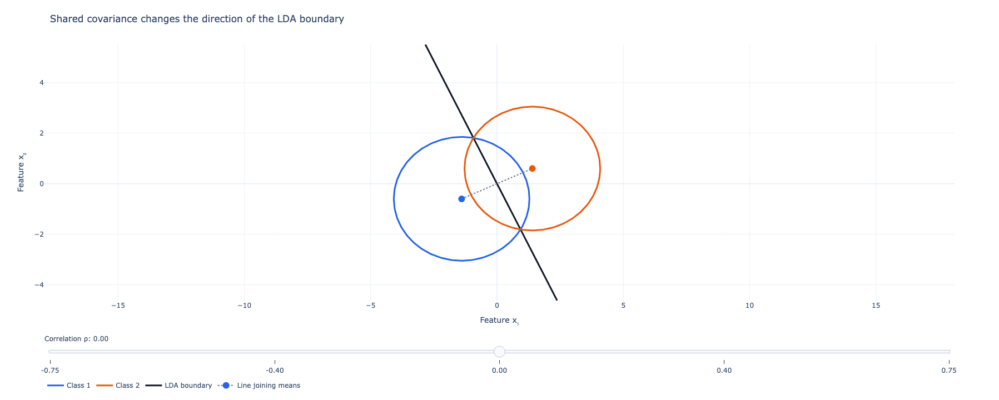

In [14]:
correlations = [-0.75, -0.4, 0.0, 0.4, 0.75]
angles = np.linspace(0, 2 * np.pi, 200)
unit_circle = np.vstack([np.cos(angles), np.sin(angles)])

fig = go.Figure()
for rho in correlations:
    covariance = np.array([
        [1.8, rho * np.sqrt(1.8 * 1.5)],
        [rho * np.sqrt(1.8 * 1.5), 1.5],
    ])
    # A Cholesky transform turns a circle into a covariance ellipse.
    ellipse_offsets = 2 * np.linalg.cholesky(covariance) @ unit_circle
    for mean, label in [(true_mean_1, 1), (true_mean_2, 2)]:
        ellipse = mean[:, None] + ellipse_offsets
        fig.add_trace(go.Scatter(
            x=ellipse[0], y=ellipse[1], mode="lines",
            line=dict(color=COLORS[label], width=3), name=f"Class {label}",
            visible=(rho == 0.0),
        ))
    normal = np.linalg.solve(covariance, true_mean_1 - true_mean_2)
    midpoint = (true_mean_1 + true_mean_2) / 2
    scores = ((grid_points - midpoint) @ normal).reshape(xx.shape)
    add_boundary(fig, scores)
    fig.data[-1].visible = (rho == 0.0)

fig.add_trace(go.Scatter(
    x=[true_mean_1[0], true_mean_2[0]], y=[true_mean_1[1], true_mean_2[1]],
    mode="lines+markers", line=dict(color="#6B7280", dash="dot"),
    marker=dict(size=12, color=[COLORS[1], COLORS[2]]), name="Line joining means",
))
steps = []
for index, rho in enumerate(correlations):
    visible = [trace_index // 3 == index for trace_index in range(3 * len(correlations))]
    visible.append(True)  # Keep the means visible.
    steps.append(dict(label=f"{rho:.2f}", method="update",
                      args=[{"visible": visible}]))
format_2d(fig, "Shared covariance changes the direction of the LDA boundary")
fig.update_layout(
    height=720, margin=dict(b=170), legend=dict(y=-0.30),
    sliders=[dict(active=2, steps=steps, y=-0.08,
                  currentvalue=dict(prefix="Correlation ρ: "))],
)
fig.show()

## 9. Optional contrast: different covariances give QDA

Now change the population model so the two covariances differ. Compare the full
Gaussian log densities, including the determinant terms. There is generally no
shared quadratic term to cancel, so the boundary can curve.

This example uses specified parameters to isolate the effect of covariance.
We deliberately omit the original observations because they came from a different,
shared-covariance model.

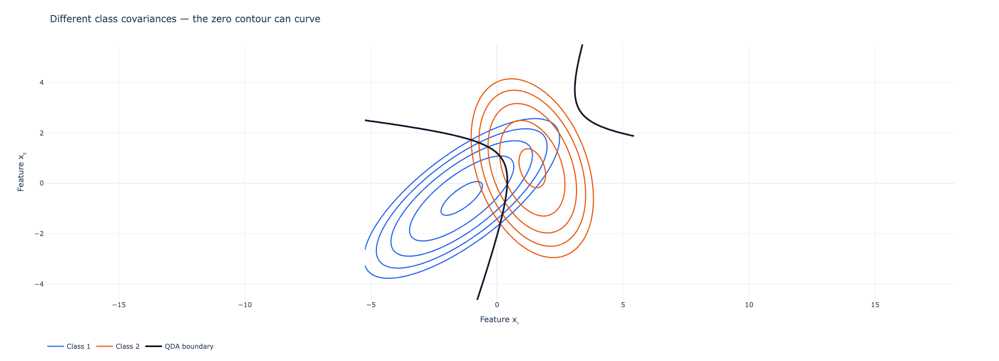

In [15]:
qda_covariance_1 = np.array([[1.8, 1.1], [1.1, 1.2]])
qda_covariance_2 = np.array([[0.7, -0.35], [-0.35, 1.5]])

qda_gaussian_1 = multivariate_normal(true_mean_1, qda_covariance_1)
qda_gaussian_2 = multivariate_normal(true_mean_2, qda_covariance_2)
qda_difference = (
    qda_gaussian_1.logpdf(grid_points) - qda_gaussian_2.logpdf(grid_points)
).reshape(xx.shape)  # Equal log priors cancel.

fig = go.Figure()
for distribution, label in [(qda_gaussian_1, 1), (qda_gaussian_2, 2)]:
    log_density = distribution.logpdf(grid_points).reshape(xx.shape)
    fig.add_trace(go.Contour(
        x=grid_x, y=grid_y, z=log_density,
        contours=dict(start=-6, end=-2, size=1, coloring="none"),
        line=dict(color=COLORS[label], width=2), showscale=False,
        name=f"Class {label}", showlegend=True,
    ))
add_boundary(fig, qda_difference, name="QDA boundary")
format_2d(fig, "Different class covariances — the zero contour can curve").show()